# Day 2 · Joins & Realized Return by Grade

*Work log: a cleaned version of my working notebook. The polished analysis lives in [`../01`–`05`](../).*

**Goals:** compare INNER JOIN and LEFT JOIN, then test the hypothesis that *lower grades' interest rates don't cover their losses*.

**Key result:** the hypothesis is **rejected**: every grade is profitable. But realized return peaks in grade B (8.3%) and falls to 2.2% in grade G, so higher risk is **not compensated**.

## 1. Setup

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = (Path.cwd().parents[1] / "Data").resolve()   # project_root/Data
con = duckdb.connect()

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)

In [2]:
# Rebuild the analysis views (DuckDB views are in-memory and reset every session)

# loans: every accepted loan
con.sql(f"""
CREATE OR REPLACE VIEW loans AS
SELECT *
FROM '{DATA}/accepted.parquet'
""")

# loans_clean: drop the 33 file-footer rows and parse the text issue date ('Dec-2015') into a real date
con.sql("""
CREATE OR REPLACE VIEW loans_clean AS
SELECT *,
       strptime(issue_d, '%b-%Y') AS issue_date
FROM loans
WHERE loan_status IS NOT NULL
""")

# cohort: 36-month loans issued 2014-2015, all matured by Dec-2018 so outcomes are final
con.sql("""
CREATE OR REPLACE VIEW cohort AS
SELECT *
FROM loans_clean
WHERE issue_date BETWEEN '2014-01-01' AND '2015-12-31'
  AND TRIM(term) = '36 months'
""")

# rejected: declined applications
con.sql(f"""
CREATE OR REPLACE VIEW rejected AS
SELECT *
FROM '{DATA}/rejected.parquet'
""")

con.sql("SHOW TABLES").df()

,name
0,cohort
1,loans
2,loans_clean
3,rejected


## 2. INNER JOIN vs. LEFT JOIN
To see the difference, I simulate a rejected table that only has data from 2012 onward.

In [3]:
join_sql = """
WITH a AS (
    SELECT YEAR(issue_date) AS application_year,
           COUNT(*)         AS n_accepted
    FROM loans_clean
    GROUP BY application_year
),
r AS (
    SELECT YEAR("Application Date") AS application_year,
           COUNT(*)                 AS n_rejected
    FROM rejected
    WHERE YEAR("Application Date") >= 2012
    GROUP BY application_year
)
SELECT a.application_year,
       a.n_accepted,
       r.n_rejected,
       ROUND(a.n_accepted * 1.0 / (a.n_accepted + r.n_rejected), 4) AS approval_rate
FROM a
{join} r ON a.application_year = r.application_year
ORDER BY a.application_year
"""

# INNER JOIN keeps only years present in both tables -> 7 rows (2012-2018)
con.sql(join_sql.format(join="JOIN")).df()

,application_year,n_accepted,n_rejected,approval_rate
0,2012,53367,337277,0.1366
1,2013,134814,760942,0.1505
2,2014,235629,1933700,0.1086
3,2015,421095,2859379,0.1284
4,2016,434407,4769874,0.0835
5,2017,443579,7072573,0.0590
6,2018,495242,9496782,0.0496


In [4]:
# LEFT JOIN keeps every year from the left table -> 12 rows; 2007-2011 get NULL
# (any arithmetic with NULL is NULL, so approval_rate is NULL there too)
con.sql(join_sql.format(join="LEFT JOIN")).df()

,application_year,n_accepted,n_rejected,approval_rate
0,2007,603,<NA>,NaN
1,2008,2393,<NA>,NaN
2,2009,5281,<NA>,NaN
3,2010,12537,<NA>,NaN
4,2011,21721,<NA>,NaN
5,2012,53367,337277,0.1366
6,2013,134814,760942,0.1505
7,2014,235629,1933700,0.1086
8,2015,421095,2859379,0.1284
9,2016,434407,4769874,0.0835


**Takeaway:** an INNER JOIN can silently drop rows. Always compare row counts before and after a join.

## 3. Realized return
`realized return = total collected ÷ total lent − 1`

* `funded_amnt`: the amount actually lent
* `total_pymnt`: everything collected (principal, interest, fees, recoveries)

All loans are included, both good and bad, so losses on charged-off loans offset the interest earned on good ones. The numerator and denominator cover the same population.

In [5]:
con.sql("""
SELECT SUM(total_pymnt) AS total_received,
       SUM(funded_amnt) AS total_funded,
       ROUND(SUM(total_pymnt) * 1.0 / SUM(funded_amnt) - 1, 4) AS total_return
FROM cohort
""").df()

,total_received,total_funded,total_return
0,6.094409e+09,5.672502e+09,0.0744


In [6]:
df = con.sql("""
SELECT grade,
       COUNT(*) AS n_loans,
       ROUND(AVG(CASE WHEN loan_status IN ('Charged Off', 'Late (31-120 days)') THEN 1
                        WHEN loan_status = 'Fully Paid' THEN 0 END), 4) AS bad_rate,
       ROUND(SUM(total_pymnt) * 1.0 / SUM(funded_amnt) - 1, 4) AS total_return
FROM cohort
GROUP BY grade
ORDER BY grade
""").df()
df

,grade,n_loans,bad_rate,total_return
0,A,105465,0.0542,0.0713
1,B,145243,0.1148,0.0828
2,C,121499,0.1864,0.0763
3,D,53250,0.2467,0.0643
4,E,16516,0.3036,0.0447
5,F,3343,0.3479,0.0439
6,G,427,0.4198,0.0219


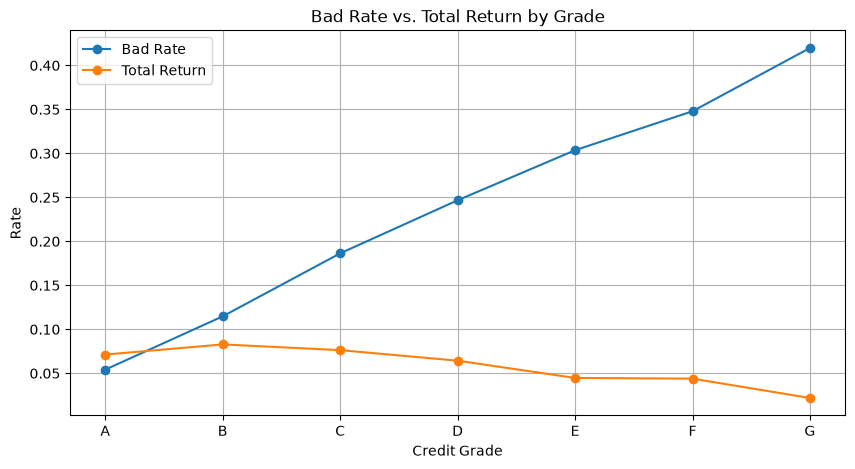

In [7]:
plt.figure(figsize=(10, 5))
plt.plot(df["grade"], df["bad_rate"], label="Bad Rate", marker="o")
plt.plot(df["grade"], df["total_return"], label="Total Return", marker="o")
plt.title("Bad Rate vs. Total Return by Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Rate")
plt.grid(True)
plt.legend()
plt.show()

**Findings**
* All grades are profitable, so the original hypothesis is rejected.
* Risk and return move in **opposite directions** after grade B: G carries 7.8× the bad rate of A but earns about one third of A's return.
* Simply raising rates on low grades would likely worsen **adverse selection**. A better option is to tighten approval or cap exposure for E–G and shift volume toward B–C.

**Note on data leakage:** `total_pymnt` is fine for evaluating results after the fact, but it must never be used as a model feature, because it isn't known at application time and directly reflects the outcome.